In [1]:
%pip install requests pandas chess zstandard scikit-learn matplotlib

  Using cached matplotlib-3.11.2-cp312-cp312-macosx_11_0_arm64.whl.metadata (80 kB)
  Using cached scipy-1.18.1-cp312-cp312-macosx_14_0_arm64.whl.metadata (62 kB)
  Using cached contourpy-1.4.0-cp312-cp312-macosx_11_0_arm64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-macosx_11_0_arm64.whl.metadata (5.2 kB)
  Using cached pillow-12.3.0-cp312-cp312-macosx_11_0_arm64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 1.2 MB/s  0:00:06 eta 0:00:010m
Using cached matplotlib-3.11.2-cp312-cp312-macosx_11_0_arm64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp312-cp312-macosx_11_0_arm64.whl (284 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 2.2 MB/s  0:00:01 eta 0:00:01
Using cached kiwisolver-1.5.1-cp312-cp312-macosx_11_0_arm64.whl (64 kB)
Using cached pil

In [10]:
import io, csv, random
import requests
import zstandard as zstd
import numpy as np
import pandas as pd
import chess
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

random.seed(42)
rng = np.random.default_rng(42)


In [11]:
url = "https://database.lichess.org/lichess_db_puzzle.csv.zst"
P = 0.002   # keep ~0.2% of rows, so ~10,000 puzzles; then I subsample 5,000

response = requests.get(url, stream=True)
response.raise_for_status()
dctx = zstd.ZstdDecompressor()

rows = []
with dctx.stream_reader(response.raw) as reader:
    text_stream = io.TextIOWrapper(reader, encoding="utf-8")
    csv_reader = csv.reader(text_stream)
    header = next(csv_reader)
    for row in csv_reader:
        if random.random() < P:
            rows.append(row)

sample = pd.DataFrame(rows, columns=header)
print("Extracted:", sample.shape)

df = sample.sample(5000, random_state=42).reset_index(drop=True)  # if you got fewer than 5000, increase P
df.to_csv("puzzles_sample.csv", index=False)
print("Saved:", df.shape)

Extracted: (12070, 11)
Saved: (5000, 11)


In [12]:
df = pd.read_csv("puzzles_sample.csv", dtype=str, keep_default_na=False)
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (5000, 11)


,PuzzleId,FEN,Moves,Rating,RatingDeviation,Popularity,NbPlays,Themes,GameUrl,OpeningTags,DailyDate
0,oq6vQ,4B3/5pk1/b2b2p1/3Pp2p/1p2P2P/5P1Q/1p1N2PK/q7 b...,g7f8 h3d7 d6e7 d5d6,1447,77,93,1611,crushing endgame master short,https://lichess.org/jT3jNEa8/black#84,,
1,OWTIi,8/4r1kp/2R3p1/p7/P7/4p3/4R1PP/1r3BK1 w - - 0 38,e2c2 e3e2 c2e2 e7e2,1155,98,92,1225,advancedPawn crushing endgame master masterVsM...,https://lichess.org/O99LI0TA#75,,
2,uITK7,3rr2k/p1p3p1/1b3q1p/8/4Q3/2P2NN1/PP3PPP/R1B3K1...,e4a4 e8e1 g3f1 d8d1,1986,77,92,312,advantage middlegame short,https://lichess.org/43TuRm0v#53,,
3,T8zSk,6k1/p5bp/4Q1p1/q7/3r1p2/1P3P1P/P3P1K1/2R5 b - ...,g8h8 e6e8 g7f8 e8f8,1199,81,94,803,endgame mate mateIn2 short,https://lichess.org/jkUXlG71/black#60,,
4,rPjyU,r2qkb1r/pp3ppp/n1p5/3Ppb2/2P1p3/2N1P3/PP2B1PP/...,e2g4 d8h4 g2g3 h4g4 d1g4 f5g4,1437,75,84,1942,advantage long middlegame,https://lichess.org/XH7lc4OU#17,Indian_Defense Indian_Defense_Normal_Variation,


In [13]:
print((df == "").sum())

PuzzleId              0
FEN                   0
Moves                 0
Rating                0
RatingDeviation       0
Popularity            0
NbPlays               0
Themes                0
GameUrl               0
OpeningTags        4040
DailyDate          5000
dtype: int64


           Rating  RatingDeviation   Popularity       NbPlays
count  5000.00000      5000.000000  5000.000000   5000.000000
mean   1472.06320        87.524000    86.305000   1797.699200
std     544.62854        27.666285    14.370723   4097.657658
min     399.00000        71.000000     0.000000      0.000000
25%    1042.00000        76.000000    83.000000    117.000000
50%    1419.00000        79.000000    90.000000    409.000000
75%    1868.00000        89.000000    94.000000   1411.250000
max    3222.00000       500.000000   100.000000  38909.000000


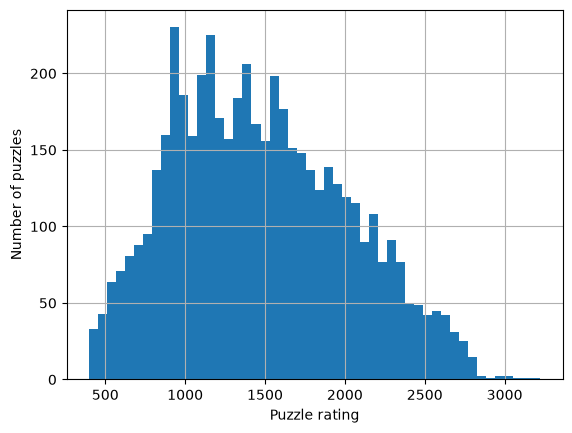

In [14]:
for c in ["Rating", "RatingDeviation", "Popularity", "NbPlays"]:
    df[c] = pd.to_numeric(df[c])

print(df[["Rating", "RatingDeviation", "Popularity", "NbPlays"]].describe())
df["Rating"].hist(bins=50)
plt.xlabel("Puzzle rating"); plt.ylabel("Number of puzzles"); plt.show()

In [15]:
df["n_moves"] = df["Moves"].str.split().str.len()
print(df["n_moves"].value_counts().sort_index())

n_moves
2      727
4     2625
6     1250
8      270
10      94
12      22
14       5
16       2
18       4
26       1
Name: count, dtype: int64


Puzzle ID: oq6vQ
Correct move: h3d7
Number of legal moves: 19
Correct move is legal: True


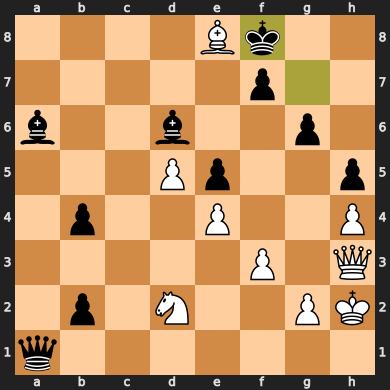

In [16]:
row = df.iloc[0]
board = chess.Board(row["FEN"])
moves = row["Moves"].split()

board.push_uci(moves[0])                  # the opponent's move
correct_move = chess.Move.from_uci(moves[1])

print("Puzzle ID:", row["PuzzleId"])
print("Correct move:", correct_move)
print("Number of legal moves:", board.legal_moves.count())
print("Correct move is legal:", correct_move in board.legal_moves)
board

In [17]:
VAL = {chess.PAWN: 1, chess.KNIGHT: 3, chess.BISHOP: 3,
       chess.ROOK: 5, chess.QUEEN: 9, chess.KING: 0}

def material(board, color):
    return sum(VAL[p.piece_type] for p in board.piece_map().values() if p.color == color)

def candidates(row):
    board = chess.Board(row["FEN"])
    moves = row["Moves"].split()
    board.push_uci(moves[0])              # the opponent's move
    correct = moves[1]                    # the correct move

    me, opp = board.turn, not board.turn
    balance = material(board, me) - material(board, opp)
    n_legal = board.legal_moves.count()

    out = []
    for m in list(board.legal_moves):
        piece = board.piece_at(m.from_square)

        if board.is_en_passant(m):
            captured_value = 1
        elif board.is_capture(m):
            captured_value = VAL[board.piece_at(m.to_square).piece_type]
        else:
            captured_value = 0

        is_capture = int(board.is_capture(m))
        gives_check = int(board.gives_check(m))
        from_attacked = int(board.is_attacked_by(opp, m.from_square))

        board.push(m)
        to_attacked = int(board.is_attacked_by(opp, m.to_square))
        gives_mate = int(board.is_checkmate())
        opp_replies = board.legal_moves.count()
        board.pop()

        out.append({
            "PuzzleId": row["PuzzleId"],
            "uci": m.uci(),
            "label": int(m.uci() == correct),
            "piece_type": piece.piece_type,
            "is_capture": is_capture,
            "captured_value": captured_value,
            "gives_check": gives_check,
            "gives_mate": gives_mate,
            "is_promotion": int(m.promotion is not None),
            "from_attacked": from_attacked,
            "to_attacked": to_attacked,
            "opp_replies": opp_replies,
            "material_balance": balance,
            "n_legal": n_legal,
        })
    return out

cand = pd.DataFrame([c for _, r in df.iterrows() for c in candidates(r)])
print("Candidates:", cand.shape)
print("Legal moves per puzzle (mean):", cand.groupby("PuzzleId").size().mean())
print("Share of correct moves:", cand["label"].mean())

Candidates: (152713, 14)
Legal moves per puzzle (mean): 30.5426
Share of correct moves: 0.03274115497698297


In [18]:
assert (cand.groupby("PuzzleId")["label"].sum() == 1).all()
cand.head()

,PuzzleId,uci,label,piece_type,is_capture,captured_value,gives_check,gives_mate,is_promotion,from_attacked,to_attacked,opp_replies,material_balance,n_legal
0,oq6vQ,e8f7,0,3,1,1,0,0,0,1,1,31,-1,19
1,oq6vQ,e8d7,0,3,0,0,0,0,0,1,0,33,-1,19
2,oq6vQ,e8c6,0,3,0,0,0,0,0,1,0,33,-1,19
3,oq6vQ,e8b5,0,3,0,0,0,0,0,1,1,29,-1,19
4,oq6vQ,e8a4,0,3,0,0,0,0,0,1,1,32,-1,19


In [19]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(cand, groups=cand["PuzzleId"]))
train = cand.iloc[train_idx].copy()
test = cand.iloc[test_idx].copy()

print("Train puzzles:", train["PuzzleId"].nunique(), "| test puzzles:", test["PuzzleId"].nunique())
print("Puzzles in both:", len(set(train["PuzzleId"]) & set(test["PuzzleId"])))  # must be 0

Train puzzles: 4000 | test puzzles: 1000
Puzzles in both: 0


I split train and test by puzzle, 4,000 and 1,000, so moves from the same position never appear in both. A random move gets 5% top-1 and 14% top-3. A simple checks and captures rule already gets 36% and 75%. So my model has to beat 75% top-3 to show it learned something.

In [20]:
def topk(d, score, ks=(1, 3)):
    d = d.copy()
    d["_s"] = np.asarray(score) + rng.random(len(d)) * 1e-6   # random tie-break
    d["_r"] = d.groupby("PuzzleId")["_s"].rank(ascending=False, method="first")
    good = d[d["label"] == 1]
    return {f"top{k}": (good["_r"] <= k).mean() for k in ks}

results = {}

# Benchmark 1: random legal move
results["Random"] = topk(test, np.zeros(len(test)))

# Benchmark 2: checks-and-captures heuristic
heur = 3 * test["gives_check"] + test["is_capture"] * (1 + test["captured_value"])
results["Checks/captures heuristic"] = topk(test, heur.values)

pd.DataFrame(results).T

,top1,top3
Random,0.051,0.142
Checks/captures heuristic,0.360,0.748


A random guess finds the correct move in the top three 14% of the time, a simple checks-and-captures rule 75% of the time, so my model has to beat 75% to show it learned something

Next I’ll fit a logistic regression, then a small neural network. If neither beats the rule, I’ll report that as a result.